# Chapter 1, Problem 5 — one experiment, two observers

**Problem (paraphrased).**

- **(a)** Use a spacetime diagram of observer $\mathcal O$ to describe this experiment: two bursts of particles with speed $0.5$ are emitted from $x = 0$ at $t = -2\ \text{m}$, one moving in $+x$, the other in $-x$. They reach detectors at $x = \pm2\ \text{m}$. After a delay of $0.5\ \text{m}$, each detector sends a signal back to $x = 0$ at speed $0.75$.
- **(b)** The signals arrive back at $x = 0$ at the same event (the diagram must show this). From this the experimenter concludes that the detectors sent their signals simultaneously, since he knows they are equal distances from $x = 0$. Explain why this conclusion is valid.
- **(c)** A second observer $\bar{\mathcal O}$ moves with speed $0.75$ in the **negative** $x$ direction relative to $\mathcal O$. Draw $\bar{\mathcal O}$'s spacetime diagram and depict the experiment in it. Does $\bar{\mathcal O}$ conclude that the detectors sent their signals simultaneously? If not, which signal was sent first?
- **(d)** Compute the interval $\Delta s^2$ between the events at which the detectors emitted their signals, using both $\mathcal O$'s and $\bar{\mathcal O}$'s coordinates.

**Event labels** (used throughout):

| event | description |
|---|---|
| $\mathcal A$ | both bursts emitted at $x=0$ |
| $\mathcal B$ | right-moving burst reaches detector at $x=+2$ |
| $\mathcal C$ | left-moving burst reaches detector at $x=-2$ |
| $\mathcal D$ | right detector sends its signal (after the delay) |
| $\mathcal E$ | left detector sends its signal |
| $\mathcal F$ | both signals arrive back at $x=0$ |

In [1]:
import numpy as np
import sympy as sp
from schutz_gr import gamma, lorentz, inverse_lorentz, interval_tx, velocity_seen_by
from schutz_gr.diagrams import SpacetimeDiagram, COLORS

%config InlineBackend.figure_format = 'retina'
R = sp.Rational

## (a) The experiment in $\mathcal O$'s frame

Work entirely in $\mathcal O$'s coordinates $(t, x)$, in metres.

**Event $\mathcal A$.** Given directly: $\boxed{\mathcal A = (t, x) = (-2,\ 0)}$.

**Burst world lines.** Each burst moves at constant speed $0.5$ from $\mathcal A$:
$$
x_{\pm}(t) = \pm\,0.5\,(t - t_{\mathcal A}) = \pm\,0.5\,(t + 2).
$$

**Detections $\mathcal B$, $\mathcal C$.** Set $x_\pm = \pm2$:
$$
0.5\,(t + 2) = 2 \;\Rightarrow\; t = 2 .
$$
Both bursts take $\Delta t = (2\ \text{m})/0.5 = 4$ m. So $\boxed{\mathcal B = (2,\ +2),\quad \mathcal C = (2,\ -2)}$.

**Detector world lines.** The detectors are at rest in $\mathcal O$: vertical lines $x = \pm2$.

**Signal emissions $\mathcal D$, $\mathcal E$.** Each detector waits $0.5$ m of its own time. Being at rest in $\mathcal O$, its proper time equals $\mathcal O$'s coordinate time, so $t = 2 + 0.5 = 2.5$:
$$
\boxed{\mathcal D = (2.5,\ +2),\quad \mathcal E = (2.5,\ -2)}.
$$

**Return signals.** Speed $0.75$ toward the origin:
$$
x_{\mathcal D}(t) = 2 - 0.75\,(t - 2.5),\qquad x_{\mathcal E}(t) = -2 + 0.75\,(t - 2.5).
$$

**Arrival $\mathcal F$.** Set $x = 0$ in either: $t = 2.5 + 2/0.75 = 2.5 + \tfrac83 = \tfrac{31}{6} \approx 5.167$. Both give the *same* $t$, so both signals arrive at a single event:
$$
\boxed{\mathcal F = \left(\tfrac{31}{6},\ 0\right) \approx (5.167,\ 0)}.
$$

In [2]:
# exact event coordinates in O: (t, x)
tA, xA = R(-2), R(0)
u, w, delay, L = R(1, 2), R(3, 4), R(1, 2), R(2)     # burst speed, signal speed, delay, detector distance

tB = tA + L / u;      B = (tB, L)
C = (tB, -L)
D = (tB + delay, L);  E = (tB + delay, -L)
tF = D[0] + L / w;    F = (tF, R(0))
A = (tA, xA)

events_O = dict(A=A, B=B, C=C, D=D, E=E, F=F)
for k, (T, X) in events_O.items():
    print(f"{k}: t = {str(T):>5s} ≈ {float(T):6.3f},   x = {str(X):>3s}")

A: t =    -2 ≈ -2.000,   x =   0
B: t =     2 ≈  2.000,   x =   2
C: t =     2 ≈  2.000,   x =  -2
D: t =   5/2 ≈  2.500,   x =   2
E: t =   5/2 ≈  2.500,   x =  -2
F: t =  31/6 ≈  5.167,   x =   0


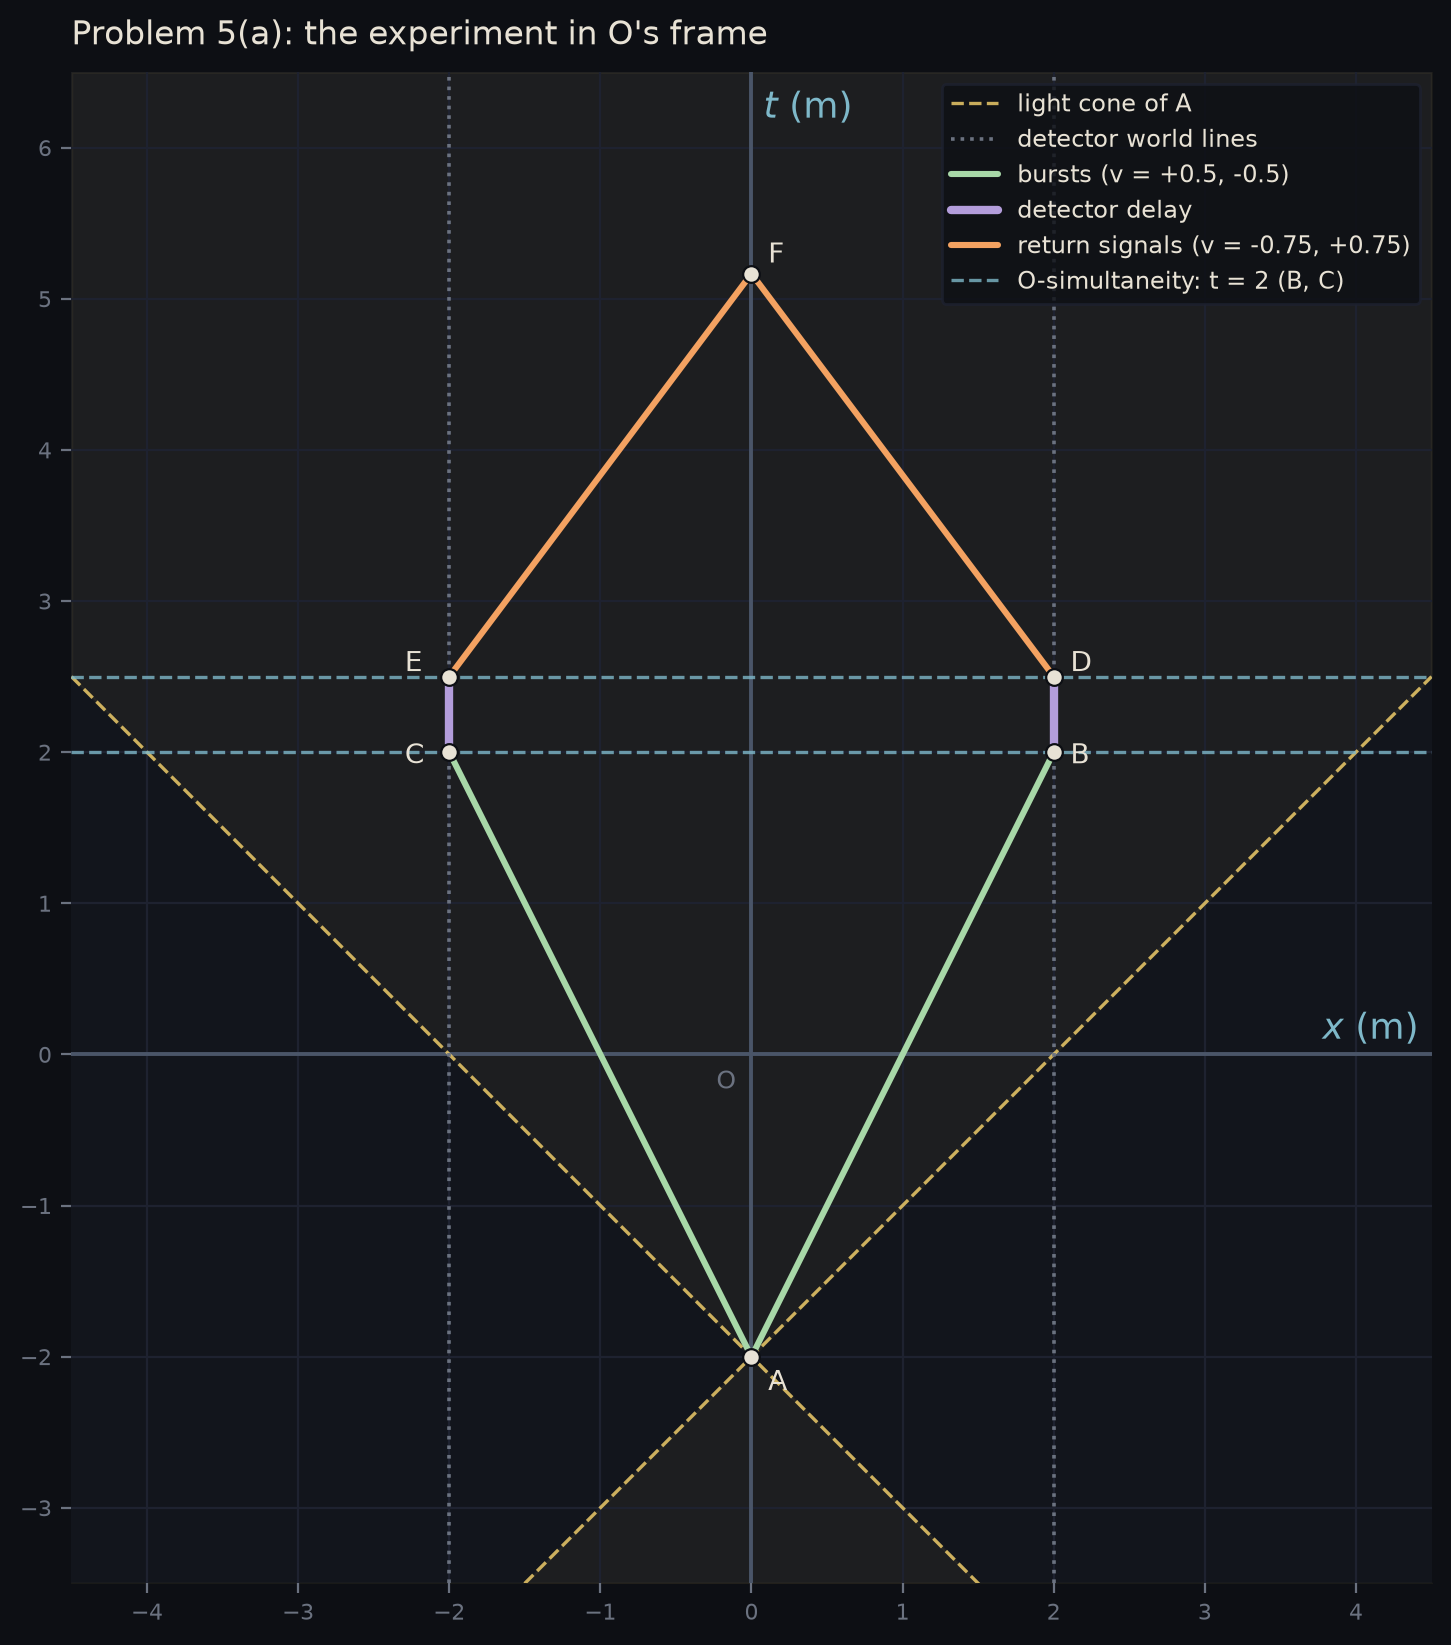

In [3]:
def draw_experiment(ev, vel, title, tlabel="t", xlabel="x", observer="O", xlim=(-4.5, 4.5), tlim=(-3.5, 6.5),
                    detector_v=0.0, sim_lines=None):
    # ev: dict of event -> (t, x) floats; vel: velocities of bursts/signals in this frame (for labels only)
    d = SpacetimeDiagram(xlim=xlim, tlim=tlim, title=title, size=7.5, tlabel=tlabel, xlabel=xlabel, observer=observer)
    d.light_cone(t0=ev["A"][0], x0=ev["A"][1], label="light cone of A", color="gold")
    seg = lambda P, Q, **kw: d.line([P[1], Q[1]], [P[0], Q[0]], **kw)
    # detector world lines: through B (and D), and through C (and E)
    for P in ("B", "C"):
        T0, X0 = ev[P]
        T = np.array(tlim)
        d.line(X0 + detector_v * (T - T0), T, color="grey", ls=":", lw=1.3,
               label="detector world lines" if P == "B" else None)
    seg(ev["A"], ev["B"], color="green", lw=2.2, label=f"bursts (v = {vel['AB']:+.3g}, {vel['AC']:+.3g})")
    seg(ev["A"], ev["C"], color="green", lw=2.2)
    seg(ev["B"], ev["D"], color="violet", lw=3.0, label="detector delay")
    seg(ev["C"], ev["E"], color="violet", lw=3.0)
    seg(ev["D"], ev["F"], color="amber", lw=2.2, label=f"return signals (v = {vel['DF']:+.3g}, {vel['EF']:+.3g})")
    seg(ev["E"], ev["F"], color="amber", lw=2.2)
    if sim_lines:
        for (T, slope, lab) in sim_lines:
            d.simultaneity_line(lambda X, T=T, s=slope: T + s * X, color="teal", ls="--", lw=1.2, alpha=0.8, label=lab)
    offs = dict(A=(6, -12), B=(6, -4), C=(-16, -4), D=(6, 2), E=(-16, 2), F=(6, 4))
    for k, (T, X) in ev.items():
        d.event(T, X, name=k, color="text", offset=offs[k])
    return d

evO = {k: (float(T), float(X)) for k, (T, X) in events_O.items()}
velO = dict(AB=0.5, AC=-0.5, DF=-0.75, EF=0.75)
d = draw_experiment(evO, velO, "Problem 5(a): the experiment in O's frame",
                    sim_lines=[(2.0, 0, "O-simultaneity: t = 2 (B, C)"), (2.5, 0, None)])
d.show(loc="upper right")

Reading the diagram: the burst world lines (green) are less steep than the signal lines (amber) because $0.5 < 0.75$; both are steeper than the $45^\circ$ light cone. The figure is mirror-symmetric about $x = 0$, which is why $\mathcal B,\mathcal C$ sit on one horizontal line, $\mathcal D,\mathcal E$ on another, and the two signals meet on the axis.

## (b) Why $\mathcal O$'s conclusion is valid

Run the argument *backwards*, as $\mathcal O$ would if only $\mathcal F$ were observed:

1. Both signals arrive at the single event $\mathcal F$, at time $t_{\mathcal F}$.
2. In $\mathcal O$'s frame, both signals travel the **same distance**, $2$ m, at the **same speed**, $0.75$. So each journey took the same time, $\Delta t = 2/0.75 = 8/3$ m.
3. Therefore both were sent at $t = t_{\mathcal F} - 8/3$: **$\mathcal D$ and $\mathcal E$ are simultaneous in $\mathcal O$.**
4. The detectors are at rest in $\mathcal O$ and each waited $0.5$ m of proper time = $0.5$ m of $\mathcal O$-time, so the detections $\mathcal B,\mathcal C$ were at $t_{\mathcal D} - 0.5$: **also simultaneous in $\mathcal O$.**

**Where the frame-dependence enters.** Step 2 assumed the signals have *equal speeds* and cover *equal distances*. Both facts are true in $\mathcal O$ only.

- For a signal at speed $0.75 < 1$, velocities transform by the composition law (eq. 1.13): an observer moving relative to $\mathcal O$ sees the two signals with *different* speeds (computed in (c): $0$ and $+0.96$ for $\bar{\mathcal O}$).
- The detectors are moving in $\bar{\mathcal O}$'s frame, so the distances from each emission event to the meeting place are not equal either.

So $\bar{\mathcal O}$, running the same backwards argument with $\bar{\mathcal O}$'s own speeds and distances, concludes the signals were *not* sent simultaneously. Both conclusions are correct; simultaneity is frame-dependent.

The one thing every observer agrees on is that $\mathcal F$ is a single event — the two signals meet, which is a coincidence of world lines. Contrast this with **light** signals: speed 1 in every frame, so the "equal speed" part of the argument would hold for everyone — which is exactly why Einstein's synchronization uses light (§1.5). Even then only $\mathcal O$ has the detectors equidistant *at rest*, so only $\mathcal O$ would conclude simultaneity.

## (c) The experiment in $\bar{\mathcal O}$'s frame ($v = -0.75$)

$\bar{\mathcal O}$ moves in the **negative** $x$ direction, so in Eq. (1.12) we use $v = -0.75$: $\bar t = \gamma(t + 0.75\,x)$, $\bar x = \gamma(x + 0.75\,t)$.

**Lorentz factor:**
$$
\gamma = \frac{1}{\sqrt{1 - 0.75^2}} = \frac{1}{\sqrt{0.4375}} = \frac{4}{\sqrt7} \approx 1.5119 .
$$

**Transform each event.** Worked out for the two signal-emission events:

$$
\mathcal D = (2.5, 2):\quad
\bar t_{\mathcal D} = \gamma(2.5 + 0.75\cdot2) = 4\gamma = \tfrac{16}{\sqrt7} \approx 6.047,\qquad
\bar x_{\mathcal D} = \gamma(2 + 0.75\cdot2.5) = 3.875\,\gamma \approx 5.858
$$

$$
\mathcal E = (2.5, -2):\quad
\bar t_{\mathcal E} = \gamma(2.5 - 1.5) = \gamma = \tfrac{4}{\sqrt7} \approx 1.512,\qquad
\bar x_{\mathcal E} = \gamma(-2 + 1.875) = -0.125\,\gamma \approx -0.189
$$

$$
\boxed{\bar t_{\mathcal D} - \bar t_{\mathcal E} = 3\gamma = \tfrac{12}{\sqrt7} \approx 4.536\ \text{m} \neq 0}
$$

**No — $\bar{\mathcal O}$ does not conclude the signals were sent simultaneously. The left detector's signal ($\mathcal E$, at $x=-2$) was sent first**, about 4.5 m of time before the right one ($\mathcal D$). The same holds for the detections: $\mathcal C$ precedes $\mathcal B$ by the same amount. General formula: two events simultaneous in $\mathcal O$ ($\Delta t = 0$) separated by $\Delta x$ have
$$
\Delta\bar t = \gamma(\Delta t - v\,\Delta x) = -\gamma v\,\Delta x = -1.5119\times(-0.75)\times4 = +4.536\ \text{m}\quad(\text{for } \bar t_{\mathcal D} - \bar t_{\mathcal E}).
$$
The event farther along $\bar{\mathcal O}$'s direction of motion (here $-x$) happens first for $\bar{\mathcal O}$.

The full table, and the velocities as $\bar{\mathcal O}$ measures them using $\bar w = (w - v)/(1 - wv)$:

In [4]:
v = R(-3, 4)          # Ō moves in the NEGATIVE x direction
g = gamma(v)
print("gamma =", sp.nsimplify(g), "≈", sp.N(g, 6))
print()
events_Ob = {}
print(f"{'event':6s} {'t (O)':>7s} {'x (O)':>7s}   {'t̄ (Ō)':>16s} {'x̄ (Ō)':>16s}")
for k, (T, X) in events_O.items():
    Tb, Xb = (sp.nsimplify(sp.simplify(q)) for q in lorentz(T, X, v))
    events_Ob[k] = (Tb, Xb)
    print(f"{k:6s} {float(T):7.3f} {float(X):7.3f}   {str(Tb):>9s}≈{float(Tb):6.3f} {str(Xb):>9s}≈{float(Xb):6.3f}")

print("\nt̄_D − t̄_E =", sp.simplify(events_Ob['D'][0] - events_Ob['E'][0]),
      "≈", sp.N(events_Ob['D'][0] - events_Ob['E'][0], 5), " (> 0: E, the left signal, was sent first)")
print("t̄_B − t̄_C =", sp.simplify(events_Ob['B'][0] - events_Ob['C'][0]))

gamma = 4*sqrt(7)/7 ≈ 1.51186

event    t (O)   x (O)             t̄ (Ō)           x̄ (Ō)


A       -2.000   0.000   -8*sqrt(7)/7≈-3.024 -6*sqrt(7)/7≈-2.268
B        2.000   2.000   2*sqrt(7)≈ 5.292 2*sqrt(7)≈ 5.292
C        2.000  -2.000   2*sqrt(7)/7≈ 0.756 -2*sqrt(7)/7≈-0.756
D        2.500   2.000   16*sqrt(7)/7≈ 6.047 31*sqrt(7)/14≈ 5.858


E        2.500  -2.000   4*sqrt(7)/7≈ 1.512 -sqrt(7)/14≈-0.189
F        5.167   0.000   62*sqrt(7)/21≈ 7.811 31*sqrt(7)/14≈ 5.858

t̄_D − t̄_E = 12*sqrt(7)/7 ≈ 4.5356  (> 0: E, the left signal, was sent first)
t̄_B − t̄_C = 12*sqrt(7)/7


In [5]:
names = {"right burst (A→B)": u, "left burst (A→C)": -u, "signal D→F": -w, "signal E→F": w, "detectors": 0}
print(f"{'body':20s} {'w in O':>8s}   {'w̄ in Ō':>8s}")
for name, wO in names.items():
    wb = velocity_seen_by(wO, v)
    print(f"{name:20s} {float(wO):8.3f}   {str(sp.nsimplify(wb)):>8s} = {float(wb):+.4f}")

body                   w in O    w̄ in Ō
right burst (A→B)       0.500      10/11 = +0.9091
left burst (A→C)       -0.500        2/5 = +0.4000
signal D→F             -0.750          0 = +0.0000
signal E→F              0.750      24/25 = +0.9600
detectors               0.000        3/4 = +0.7500


In $\bar{\mathcal O}$'s frame:

- The detectors move at $+0.75$ (to the right).
- The right burst moves at $+0.909$ and the left burst at $+0.4$: no longer symmetric.
- The signal from $\mathcal D$ is **at rest** ($\bar w = 0$, since it moves with exactly $\bar{\mathcal O}$'s velocity, $-0.75$ in $\mathcal O$). It sits at $\bar x_{\mathcal D}$ and waits for $\mathcal O$'s origin, moving at $+0.75$, to come to it. The signal from $\mathcal E$ moves at $+0.96$. The arrival event $\mathcal F$ is still a single event.

This is exactly why $\bar{\mathcal O}$ rejects $\mathcal O$'s reasoning: in $\bar{\mathcal O}$'s frame the two signals have different speeds ($0$ and $0.96$), so arriving together does not imply leaving together.

Check: $\mathcal F$ should lie on both signal lines in $\bar{\mathcal O}$'s frame too. $\bar x_{\mathcal F} = \gamma(0 + 0.75\cdot\tfrac{31}{6}) = 3.875\gamma$, and the $\mathcal D$ signal at rest needs $\bar x_{\mathcal F} = \bar x_{\mathcal D} = 3.875\gamma$ ✓.

Now the diagram, drawn with $\bar{\mathcal O}$'s axes perpendicular (it is $\bar{\mathcal O}$'s spacetime diagram). $\mathcal O$'s lines of simultaneity through $\mathcal B,\mathcal C$ and $\mathcal D,\mathcal E$ become tilted lines; $\bar{\mathcal O}$'s horizontal lines through $\mathcal E$ (lower) and $\mathcal D$ (upper) are clearly different.

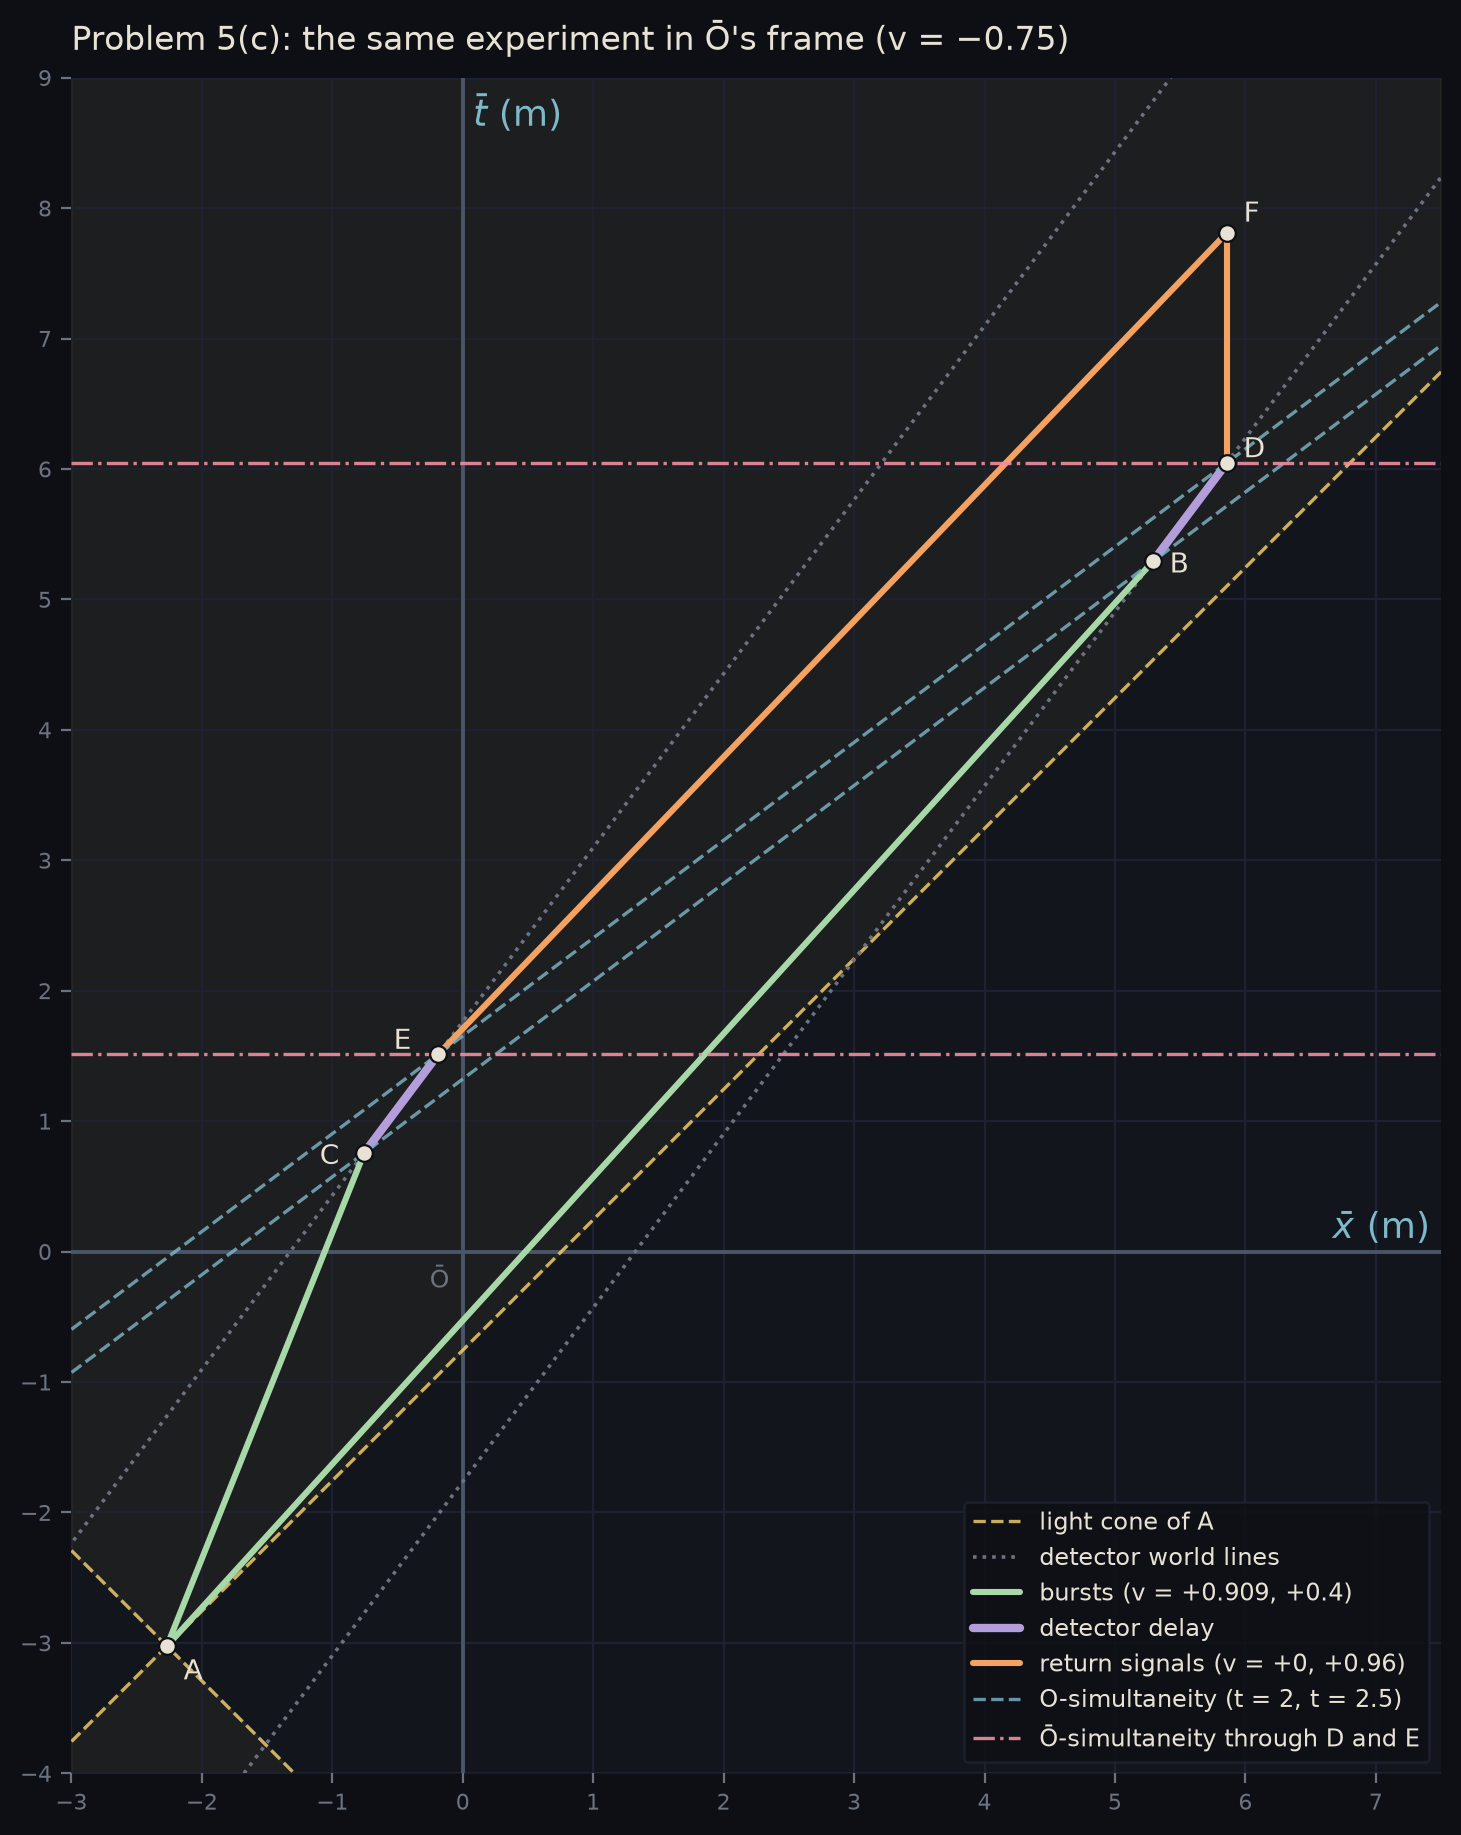

In [6]:
evOb = {k: (float(T), float(X)) for k, (T, X) in events_Ob.items()}
velOb = {k: float(velocity_seen_by(wO, v)) for k, wO in dict(AB=u, AC=-u, DF=-w, EF=w).items()}
vf, gf = float(v), float(g)
# O's line t = const = T0  in Ō coords: t = γ(t̄ + v x̄) = T0  ->  t̄ = T0/γ − v x̄  (slope −v)
d = draw_experiment(evOb, velOb, "Problem 5(c): the same experiment in Ō's frame (v = −0.75)",
                    tlabel=r"\bar t", xlabel=r"\bar x", observer="Ō",
                    xlim=(-3, 7.5), tlim=(-4, 9), detector_v=-vf,
                    sim_lines=[(2.5 / gf, -vf, "O-simultaneity (t = 2, t = 2.5)"), (2.0 / gf, -vf, None)])
for k in ("D", "E"):
    T = evOb[k][0]
    d.simultaneity_line(lambda X, T=T: T + 0 * X, color="rose", ls="-.", lw=1.2, alpha=0.9,
                        label="Ō-simultaneity through D and E" if k == "D" else None)
d.show(loc="lower right")

## (d) The interval between $\mathcal D$ and $\mathcal E$

**In $\mathcal O$:** $\Delta t = 2.5 - 2.5 = 0$, $\Delta x = 2 - (-2) = 4$ m:
$$
\Delta s^2_{\mathcal{DE}} = -(\Delta t)^2 + (\Delta x)^2 = -0 + 16 = \boxed{16\ \text{m}^2}.
$$

**In $\bar{\mathcal O}$:** from the table, $\Delta\bar t = \bar t_{\mathcal D} - \bar t_{\mathcal E} = 4\gamma - \gamma = 3\gamma$ and $\Delta\bar x = \bar x_{\mathcal D} - \bar x_{\mathcal E} = 3.875\gamma + 0.125\gamma = 4\gamma$:
$$
\Delta\bar s^2_{\mathcal{DE}} = -(3\gamma)^2 + (4\gamma)^2 = 7\gamma^2 = 7\times\frac{16}{7} = \boxed{16\ \text{m}^2}.
$$

The same. This is exactly the invariance of the interval (§1.6), which is the reason the Lorentz transformation has the form it does. Note how differently the 16 is assembled: in $\mathcal O$ it is all spatial separation; in $\bar{\mathcal O}$ the spatial part is larger ($\Delta\bar x^2 \approx 36.6$) and a time separation ($\Delta\bar t^2 \approx 20.6$) is subtracted from it.

The problem also suggests checking this by **measuring** on your hand-drawn $\bar{\mathcal O}$ diagram; with exact coordinates there is nothing to estimate, but reading $\Delta\bar t \approx 4.5$ and $\Delta\bar x \approx 6.0$ off the figure above gives $-20.3 + 36 \approx 16$ ✓.

The pair $\mathcal B,\mathcal C$ gives the same result (also $\Delta t = 0$, $\Delta x = 4$ in $\mathcal O$). Since $\Delta s^2 > 0$ the separation is **spacelike**. That's why different observers can disagree about the time order of $\mathcal D$ and $\mathcal E$ — an observer moving at $v = +0.75$ would see $\mathcal D$ first — without any causal paradox: no signal can connect them.

In [7]:
for P, Q in (("D", "E"), ("B", "C")):
    sO = interval_tx(events_O[P][0] - events_O[Q][0], events_O[P][1] - events_O[Q][1])
    sOb = sp.simplify(interval_tx(events_Ob[P][0] - events_Ob[Q][0], events_Ob[P][1] - events_Ob[Q][1]))
    print(f"Δs²({P}{Q}):  O → {sO},   Ō → {sOb}")

# All 15 pairs, to be thorough: the interval is invariant for every pair of events
keys = list(events_O)
ok = all(sp.simplify(
            interval_tx(events_O[p][0]-events_O[q][0], events_O[p][1]-events_O[q][1]) -
            interval_tx(events_Ob[p][0]-events_Ob[q][0], events_Ob[p][1]-events_Ob[q][1])) == 0
         for i, p in enumerate(keys) for q in keys[i+1:])
print("interval invariant for all 15 pairs of events:", ok)

Δs²(DE):  O → 16,   Ō → 16
Δs²(BC):  O → 16,   Ō → 16
interval invariant for all 15 pairs of events: True


## Summary

| event | $\mathcal O$: $(t, x)$ | $\bar{\mathcal O}$: $(\bar t, \bar x)$ |
|---|---|---|
| $\mathcal A$ | $(-2,\ 0)$ | $(-3.024,\ -2.268)$ |
| $\mathcal B$ | $(2,\ 2)$ | $(5.292,\ 5.292)$ |
| $\mathcal C$ | $(2,\ -2)$ | $(0.756,\ -0.756)$ |
| $\mathcal D$ | $(2.5,\ 2)$ | $(6.047,\ 5.858)$ |
| $\mathcal E$ | $(2.5,\ -2)$ | $(1.512,\ -0.189)$ |
| $\mathcal F$ | $(5.167,\ 0)$ | $(7.811,\ 5.858)$ |

- In $\mathcal O$: $\mathcal B,\mathcal C$ simultaneous ($t = 2$); $\mathcal D,\mathcal E$ simultaneous ($t = 2.5$); signals meet at $\mathcal F$, $t = 31/6$.
- In $\bar{\mathcal O}$ (moving at $-0.75$): **the left signal $\mathcal E$ is sent first**, $3\gamma = 12/\sqrt7 \approx 4.54$ m before $\mathcal D$; $\mathcal C$ precedes $\mathcal B$ by the same amount.
- $\Delta s^2_{\mathcal{DE}} = 16\ \text{m}^2$ in both frames (spacelike).